# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Zoni Zikro Manurung
- **Email:** zoni.zikro@students.mikroskil.ac.id
- **ID Dicoding:** celyeo

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik):** pertanyaan jelas, fokus pada topik tertentu, dan tidak bermakna ganda.
* **Measurable (Terukur):** pertanyaan dapat dijawab dengan angka atau metrik yang konkret.
* **Action-Oriented (Berorientasi Aksi):** hasilnya memberi arahan tindakan nyata bagi stakeholder.
* **Relevant (Relevan):** hasilnya sejalan dengan tujuan atau masalah utama bisnis.
* **Time-bound (Terikat Waktu):** pertanyaan memiliki batasan waktu yang jelas.

## Menentukan Pertanyaan Bisnis

Seluruh pertanyaan dibatasi pada pesanan berstatus *delivered* dengan tanggal pembelian **Januari 2017 sampai Agustus 2018**. Data sebelum 2017 dan setelah Agustus 2018 sangat sedikit (puluhan pesanan per bulan) sehingga tidak representatif.

- **Pertanyaan 1 (kategori produk):** Pada periode Januari 2017 sampai Agustus 2018, 10 kategori produk apa yang menghasilkan total pendapatan (jumlah `price`) terbesar, dan berapa rata-rata review score masing-masing, sehingga tim dapat menentukan kategori yang diprioritaskan untuk promosi dan kategori yang perlu perbaikan kualitas?
- **Pertanyaan 2 (pengiriman):** Berapa persentase pesanan yang tiba melewati estimasi pengiriman di setiap negara bagian (state) pelanggan pada periode Januari 2017 sampai Agustus 2018, dan berapa selisih rata-rata review score antara pesanan terlambat dan tepat waktu, sehingga tim logistik dapat menentukan state yang diprioritaskan untuk perbaikan layanan?
- **Pertanyaan 3 (pelanggan, dijawab pada Analisis Lanjutan melalui RFM):** Dengan tanggal acuan 1 September 2018, bagaimana komposisi segmen pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) pada periode Januari 2017 sampai Agustus 2018, dan segmen mana yang menyumbang proporsi pendapatan terbesar, sehingga tim pemasaran dapat menentukan segmen sasaran kampanye retensi?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', 30)

# Warna konsisten: biru = nilai utama, oranye = sorotan, abu-abu = konteks
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#b9b8b2'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': INK2, 'xtick.color': INK2,
    'ytick.color': INK2, 'font.size': 10, 'figure.dpi': 110,
})

## Data Wrangling
### Gathering Data
#### Load df pesanan, item, pembayaran, ulasan, pelanggan, produk, terjemahan kategori, dan geolokasi
Berkas `sellers` tidak dimuat karena tidak diperlukan oleh pertanyaan bisnis.

In [13]:
DATA = 'data/'
orders_df    = pd.read_csv(DATA + 'orders_dataset.csv',
                           parse_dates=['order_purchase_timestamp', 'order_approved_at',
                                        'order_delivered_carrier_date', 'order_delivered_customer_date',
                                        'order_estimated_delivery_date'])
items_df     = pd.read_csv(DATA + 'order_items_dataset.csv')
payments_df  = pd.read_csv(DATA + 'order_payments_dataset.csv')
reviews_df   = pd.read_csv(DATA + 'order_reviews_dataset.csv')
customers_df = pd.read_csv(DATA + 'customers_dataset.csv')
products_df  = pd.read_csv(DATA + 'products_dataset.csv')
trans_df     = pd.read_csv(DATA + 'product_category_name_translation.csv')
geo_df       = pd.read_csv(DATA + 'geolocation_dataset.csv')

for name, d in [('orders', orders_df), ('items', items_df), ('payments', payments_df), ('reviews', reviews_df),
                ('customers', customers_df), ('products', products_df), ('translation', trans_df), ('geolocation', geo_df)]:
    print(f'{name:12s} {d.shape}')
orders_df.head()

orders       (99441, 8)
items        (112650, 7)
payments     (103886, 5)
reviews      (99224, 7)
customers    (99441, 5)
products     (32951, 9)
translation  (71, 2)
geolocation  (1000163, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


**Insight:**
- Tabel `orders` memuat 99.441 pesanan dan menjadi tabel pusat. Ia terhubung ke `order_items` dan `order_reviews` lewat `order_id`, ke `customers` lewat `customer_id`, serta ke `products` lewat `product_id`.
- `customers` memiliki dua kunci: `customer_id` (unik per pesanan) dan `customer_unique_id` (unik per orang). Untuk analisis pelanggan (RFM) harus dipakai `customer_unique_id`.
- `geolocation` sangat besar (sekitar 1 juta baris) karena satu kode pos punya banyak titik koordinat.

### Assessing Data
#### Identifying missing value, duplicate data, inconsistent value, invalid value, dan outlier
Setiap tabel diperiksa untuk missing value, duplikasi, tipe data, dan nilai yang tidak konsisten.

In [14]:
def assess(name, d):
    na = d.isna().sum()
    print(f'=== {name} | baris: {len(d):,} | duplikat: {d.duplicated().sum():,}')
    print('missing value:', na[na > 0].to_dict() or 'tidak ada')

for name, d in [('orders', orders_df), ('items', items_df), ('payments', payments_df), ('reviews', reviews_df),
                ('customers', customers_df), ('products', products_df), ('translation', trans_df), ('geolocation', geo_df)]:
    assess(name, d)

=== orders | baris: 99,441 | duplikat: 0
missing value: {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
=== items | baris: 112,650 | duplikat: 0
missing value: tidak ada
=== payments | baris: 103,886 | duplikat: 0
missing value: tidak ada
=== reviews | baris: 99,224 | duplikat: 0
missing value: {'review_comment_title': 87656, 'review_comment_message': 58247}
=== customers | baris: 99,441 | duplikat: 0
missing value: tidak ada
=== products | baris: 32,951 | duplikat: 0
missing value: {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
=== translation | baris: 71 | duplikat: 0
missing value: tidak ada
=== geolocation | baris: 1,000,163 | duplikat: 261,831
missing value: tidak ada


In [15]:
# 1) Status pesanan dan konsistensi tanggal
print(orders_df['order_status'].value_counts(), '\n')
delivered = orders_df[orders_df['order_status'] == 'delivered']
print('Status delivered tetapi tanggal tiba kosong:', delivered['order_delivered_customer_date'].isna().sum())
print('Tanggal tiba lebih awal dari tanggal beli:',
      (delivered['order_delivered_customer_date'] < delivered['order_purchase_timestamp']).sum())

# 2) Sebaran pesanan per bulan (untuk menentukan periode analisis)
print(orders_df.groupby(orders_df['order_purchase_timestamp'].dt.to_period('M')).size().to_string())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Status delivered tetapi tanggal tiba kosong: 8
Tanggal tiba lebih awal dari tanggal beli: 0
order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [16]:
# 3) Ulasan ganda per pesanan
dup_rev = reviews_df['order_id'].duplicated().sum()
print('Pesanan dengan lebih dari satu ulasan:', dup_rev)
print('Rentang review_score:', reviews_df['review_score'].min(), '-', reviews_df['review_score'].max())

# 4) Kategori produk: missing dan nama tanpa terjemahan
print('\nProduk tanpa kategori:', products_df['product_category_name'].isna().sum())
missing_trans = set(products_df['product_category_name'].dropna()) - set(trans_df['product_category_name'])
print('Kategori tanpa terjemahan:', missing_trans)

# 5) Geolokasi: duplikasi, nama kota tidak konsisten, koordinat di luar Brasil
print('\nBaris duplikat geolokasi:', geo_df.duplicated().sum())
print('Nama kota mengandung karakter non-ASCII/simbol:', geo_df['geolocation_city'].str.contains(r'[^a-z ]', regex=True).sum())
print(geo_df.loc[geo_df['geolocation_city'].str.contains(r'[^a-z ]', regex=True), 'geolocation_city'].head(5).tolist())
inside = geo_df['geolocation_lat'].between(-34, 6) & geo_df['geolocation_lng'].between(-74, -34)
print('Koordinat di luar batas Brasil:', (~inside).sum())

# 6) Outlier harga dan ongkir
print()
print(items_df[['price', 'freight_value']].describe().round(2))
q1, q3 = items_df['price'].quantile([.25, .75])
print('Jumlah outlier harga (IQR):', (items_df['price'] > q3 + 1.5 * (q3 - q1)).sum())

Pesanan dengan lebih dari satu ulasan: 551
Rentang review_score: 1 - 5

Produk tanpa kategori: 610
Kategori tanpa terjemahan: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}

Baris duplikat geolokasi: 261831
Nama kota mengandung karakter non-ASCII/simbol: 76798
['são paulo', 'são paulo', 'são paulo', 'são paulo', 'são paulo']
Koordinat di luar batas Brasil: 42

           price  freight_value
count  112650.00      112650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max      6735.00         409.68
Jumlah outlier harga (IQR): 8427


**Steps to Take:**

| Tabel | Masalah | Jenis | Tindakan pada tahap Cleaning |
|---|---|---|---|
| `orders` | 8 pesanan berstatus *delivered* tidak memiliki tanggal tiba; 160 `order_approved_at` kosong; status selain delivered | Missing value | Hanya pesanan *delivered* dengan tanggal tiba valid yang dipakai |
| `orders` | Pesanan 2016 dan setelah Agustus 2018 jumlahnya sangat kecil | Data tidak representatif | Filter periode Januari 2017 sampai Agustus 2018 |
| `order_reviews` | 551 pesanan memiliki lebih dari satu ulasan | Duplicate data | Ambil ulasan terbaru per pesanan |
| `products` | 610 produk tanpa kategori; 2 kategori tanpa terjemahan | Missing value | Beri label `unknown`; terjemahan dilengkapi manual |
| `geolocation` | 261.831 baris duplikat, sekitar 76 ribu nama kota memuat aksen/simbol, 42 koordinat di luar Brasil, satu kode pos punya banyak koordinat | Duplicate, inconsistent, dan invalid value | Hapus duplikat, normalisasi nama kota, buang koordinat di luar Brasil, ambil titik tengah per kode pos |
| `order_items` | Harga dan ongkir memiliki ekor panjang (outlier) | Outlier | Dipertahankan karena merupakan transaksi valid; analisis memakai total dan median |

**Insight:**
- Masalah paling banyak ditemukan pada tabel `geolocation` (duplikat, nama kota tidak konsisten, koordinat tidak valid) dan `order_reviews` (ulasan ganda per pesanan).
- Tabel `orders` mengandung status selain *delivered* dan beberapa pesanan tanpa tanggal tiba, sehingga perlu disaring sebelum menghitung keterlambatan.
- Outlier harga dan ongkir dipertahankan karena merupakan transaksi valid, bukan kesalahan input.

### Cleaning Data
#### Fixing missing value, duplicate data, inconsistent value, dan invalid value
Langkah cleaning mengikuti daftar *Steps to Take* pada tahap Assessing Data.

In [17]:
# --- 1. Orders: hanya delivered, tanggal tiba valid, periode 2017-01 s.d. 2018-08
orders = orders_df[(orders_df['order_status'] == 'delivered')
                   & orders_df['order_delivered_customer_date'].notna()].copy()
orders = orders[(orders['order_purchase_timestamp'] >= '2017-01-01')
                & (orders['order_purchase_timestamp'] < '2018-09-01')]
print('Pesanan setelah filter:', len(orders), 'dari', len(orders_df))

# Fitur pengiriman
orders['delivery_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.total_seconds() / 86400
orders['delay_days']    = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.total_seconds() / 86400
orders['is_late']       = orders['delay_days'] > 0
orders['purchase_month'] = orders['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

# --- 2. Reviews: ambil ulasan terbaru per pesanan
reviews = (reviews_df.sort_values('review_answer_timestamp')
                     .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
print('Ulasan unik per pesanan:', reviews['order_id'].is_unique)

# --- 3. Products: kategori kosong -> 'unknown', lengkapi terjemahan manual
manual_trans = pd.DataFrame({
    'product_category_name': ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'],
    'product_category_name_english': ['pc_gamer', 'portable_kitchen_food_preparers']})
trans = pd.concat([trans_df, manual_trans], ignore_index=True)
products = products_df[['product_id', 'product_category_name']].merge(trans, on='product_category_name', how='left')
products['category'] = products['product_category_name_english'].fillna('unknown')
products = products[['product_id', 'category']]
print('Produk tanpa kategori setelah cleaning:', (products['category'] == 'unknown').sum(), '(diberi label unknown)')

Pesanan setelah filter: 96203 dari 99441
Ulasan unik per pesanan: True
Produk tanpa kategori setelah cleaning: 610 (diberi label unknown)


In [18]:
# --- 4. Geolocation: hapus duplikat, normalisasi nama kota, buang koordinat di luar Brasil, rata-rata per kode pos
def strip_accents(s):
    return unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode('ascii').strip()

geo = geo_df.drop_duplicates().copy()
geo['geolocation_city'] = geo['geolocation_city'].map(strip_accents)
geo = geo[geo['geolocation_lat'].between(-34, 6) & geo['geolocation_lng'].between(-74, -34)]
geo_zip = (geo.groupby('geolocation_zip_code_prefix', as_index=False)
              .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')))
print('Geolokasi: %d baris awal -> %d kode pos unik' % (len(geo_df), len(geo_zip)))
print('Nama kota dengan simbol tersisa (data kotor sisa, kolom kota tidak dipakai analisis):', geo['geolocation_city'].str.contains(r'[^a-z \-\']', regex=True).sum())

Geolokasi: 1000163 baris awal -> 19010 kode pos unik
Nama kota dengan simbol tersisa (data kotor sisa, kolom kota tidak dipakai analisis): 30


In [19]:
# --- 5. Gabungkan menjadi tabel analisis (granularitas: satu baris = satu item pesanan)
all_df = (items_df
          .merge(orders[['order_id', 'customer_id', 'purchase_month', 'order_purchase_timestamp',
                         'delivery_days', 'delay_days', 'is_late']], on='order_id', how='inner')
          .merge(reviews, on='order_id', how='left')
          .merge(products, on='product_id', how='left')
          .merge(customers_df[['customer_id', 'customer_unique_id', 'customer_state', 'customer_zip_code_prefix']],
                 on='customer_id', how='left')
          .merge(geo_zip, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
          .drop(columns=['geolocation_zip_code_prefix']))
all_df['category'] = all_df['category'].fillna('unknown')
all_df['total_value'] = all_df['price'] + all_df['freight_value']

print(all_df.shape)
print('Missing value pada kolom kunci:')
print(all_df[['review_score', 'category', 'customer_state', 'lat', 'lng']].isna().sum().to_dict())

(109872, 21)
Missing value pada kolom kunci:
{'review_score': 823, 'category': 0, 'customer_state': 0, 'lat': 289, 'lng': 289}


Sebagian kecil pesanan tidak memiliki ulasan, dan sebagian kode pos pelanggan tidak ditemukan di tabel geolokasi. Baris tersebut tidak dibuang. Perhitungan rata-rata review mengabaikan nilai kosong, dan peta hanya memakai baris yang memiliki koordinat.

In [20]:
# Tabel akhir yang juga dipakai dashboard
main = all_df[['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'purchase_month', 'category', 'price',
               'freight_value', 'total_value', 'review_score', 'delivery_days', 'delay_days', 'is_late',
               'customer_state', 'lat', 'lng']].copy()
main = main.round({'price': 2, 'freight_value': 2, 'total_value': 2, 'delivery_days': 2, 'delay_days': 2, 'lat': 3, 'lng': 3})
main.to_csv('dashboard/main_data.csv', index=False)
print(main.shape, '| ukuran berkas ~', round(main.memory_usage(deep=True).sum() / 1e6, 1), 'MB di memori')
main.head()

(109872, 15) | ukuran berkas ~ 39.1 MB di memori


,order_id,customer_unique_id,order_purchase_timestamp,purchase_month,category,price,freight_value,total_value,review_score,delivery_days,delay_days,is_late,customer_state,lat,lng
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,2017-09-13 08:59:02,2017-09-01,cool_stuff,58.90,13.29,72.19,5.0,7.61,-8.01,False,RJ,-21.763,-41.310
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,2017-04-26 10:53:06,2017-04-01,pet_shop,239.90,19.93,259.83,4.0,16.22,-2.33,False,SP,-20.223,-50.899
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,2018-01-14 14:33:31,2018-01-01,furniture_decor,199.00,17.87,216.87,5.0,7.95,-13.44,False,MG,-19.870,-44.593
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,2018-08-08 10:00:35,2018-08-01,perfumery,12.99,12.79,25.78,4.0,6.15,-5.44,False,SP,-23.106,-46.590
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,2017-02-04 13:57:51,2017-02-01,garden_tools,199.90,18.14,218.04,5.0,25.11,-15.30,False,SP,-23.243,-46.828


**Insight:**
- Setelah filter, tersisa pesanan *delivered* periode Januari 2017 sampai Agustus 2018 yang siap dianalisis.
- Setiap pesanan kini memiliki tepat satu review, kategori berbahasa Inggris, serta koordinat pelanggan (titik tengah kode pos).
- Tabel gabungan disimpan sebagai `dashboard/main_data.csv` agar dashboard memakai data yang sama persis dengan notebook.

## Exploratory Data Analysis (EDA)
### Explore ringkasan umum data

In [21]:
order_level = main.drop_duplicates('order_id')
print('Jumlah pesanan      :', order_level['order_id'].nunique())
print('Jumlah pelanggan    :', main['customer_unique_id'].nunique())
print('Total pendapatan    : R$ {:,.0f}'.format(main['price'].sum()))
print('Rata-rata review    : {:.2f}'.format(order_level['review_score'].mean()))
print('Persentase terlambat: {:.1f}%'.format(order_level['is_late'].mean() * 100))
main[['price', 'freight_value', 'review_score', 'delivery_days', 'delay_days']].describe().round(2)

Jumlah pesanan      : 96203
Jumlah pelanggan    : 93096
Total pendapatan    : R$ 13,179,778
Rata-rata review    : 4.16
Persentase terlambat: 8.1%


,price,freight_value,review_score,delivery_days,delay_days
count,109872.00,109872.00,109049.00,109872.00,109872.00
mean,119.96,19.95,4.08,12.45,-11.26
std,182.35,15.70,1.35,9.43,10.06
min,0.85,0.00,1.00,0.53,-146.02
25%,39.90,13.08,4.00,6.72,-16.30
50%,74.90,16.26,5.00,10.18,-12.03
75%,134.04,21.15,5.00,15.50,-6.46
max,6735.00,409.68,5.00,209.63,188.98


In [22]:
monthly = order_level.groupby('purchase_month').agg(pesanan=('order_id', 'count'), avg_review=('review_score', 'mean')).round(2)
monthly.T

purchase_month,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01
pesanan,750.0,1653.0,2546.00,2303.00,3545.00,3135.00,3872.00,4193.00,4150.00,4478.0,7288.00,5513.00,7069.00,6555.00,7003.00,6798.00,6749.00,6096.00,6156.00,6351.00
avg_review,4.2,4.2,4.19,4.14,4.24,4.22,4.26,4.31,4.27,4.2,3.99,4.09,4.11,3.88,3.81,4.21,4.24,4.31,4.32,4.31


### Explore Pertanyaan 1: kategori dengan pendapatan terbesar dan rata-rata review

In [23]:
cat = (main.groupby('category')
           .agg(revenue=('price', 'sum'), items=('order_id', 'count'), avg_review=('review_score', 'mean'))
           .sort_values('revenue', ascending=False))
cat['revenue_share_%'] = (cat['revenue'] / cat['revenue'].sum() * 100).round(1)
top10 = cat.head(10).copy()
print('Kontribusi 10 kategori teratas: {:.1f}% dari total pendapatan'.format(top10['revenue_share_%'].sum()))
print('Rata-rata review seluruh kategori: {:.2f}'.format(main['review_score'].mean()))
top10.round(2)

Kontribusi 10 kategori teratas: 62.5% dari total pendapatan
Rata-rata review seluruh kategori: 4.08


,revenue,items,avg_review,revenue_share_%
category,,,,
health_beauty,1229557.50,9422,4.19,9.3
watches_gifts,1163187.91,5853,4.07,8.8
bed_bath_table,1022955.77,10945,3.92,7.8
sports_leisure,952661.40,8413,4.16,7.2
computers_accessories,887944.60,7631,3.99,6.7
furniture_decor,706237.17,8095,3.96,5.4
housewares,614341.62,6783,4.11,4.7
cool_stuff,609158.00,3711,4.20,4.6
auto,577721.09,4131,4.12,4.4


In [24]:
# Kategori dengan review terendah (minimal 500 item agar tidak bias sampel kecil)
low_rev = cat[cat['items'] >= 500].sort_values('avg_review').head(5)
low_rev.round(2)

,revenue,items,avg_review,revenue_share_%
category,,,,
office_furniture,266853.43,1662,3.52,2.0
bed_bath_table,1022955.77,10945,3.92,7.8
unknown,170660.74,1535,3.94,1.3
furniture_decor,706237.17,8095,3.96,5.4
home_construction,81407.57,596,3.96,0.6


### Explore Pertanyaan 2: keterlambatan pengiriman per state dan dampaknya pada review

In [25]:
state = (order_level.groupby('customer_state')
         .agg(orders=('order_id', 'count'), late_pct=('is_late', lambda s: s.mean() * 100),
              avg_delivery=('delivery_days', 'mean'), avg_review=('review_score', 'mean'))
         .sort_values('late_pct', ascending=False))
state_big = state[state['orders'] >= 300]
print('State dengan >= 300 pesanan:', len(state_big), 'dari', len(state))
state_big.round(2).head(10)

State dengan >= 300 pesanan: 21 dari 27


,orders,late_pct,avg_delivery,avg_review
customer_state,,,,
AL,396,23.99,24.52,3.85
MA,713,19.64,21.54,3.83
PI,475,16.00,19.44,3.99
CE,1273,15.40,21.24,3.94
SE,332,15.36,21.44,3.90
BA,3253,14.05,19.33,3.93
RJ,12310,13.52,15.30,3.97
PA,942,12.42,23.76,3.91
ES,1992,12.25,15.78,4.08


In [26]:
by_late = order_level.groupby('is_late')['review_score'].agg(['mean', 'count']).round(2)
by_late.index = ['Tepat waktu', 'Terlambat']
print(by_late)
print('Selisih review: {:.2f} poin'.format(by_late.loc['Tepat waktu', 'mean'] - by_late.loc['Terlambat', 'mean']))

             mean  count
Tepat waktu  4.29  87902
Terlambat    2.57   7658
Selisih review: 1.72 poin


**Insight:**
- Terdapat 96.203 pesanan dari 93.096 pelanggan unik dengan total pendapatan sekitar R$ 13,18 juta dan rata-rata review 4,16.
- Pendapatan terpusat pada sepuluh kategori teratas (62,5%), dan `health_beauty` berada di posisi pertama.
- Hanya 8,1% pesanan tiba melewati estimasi, tetapi pesanan terlambat memiliki review rata-rata 2,57 dibanding 4,29 untuk yang tepat waktu.
- Persentase keterlambatan sangat berbeda antar state, dari sekitar 5% (PR, MG, SP) hingga 24% (AL).

## Visualization & Explanatory Analysis

### Pertanyaan 1: 10 kategori dengan pendapatan terbesar dan rata-rata review

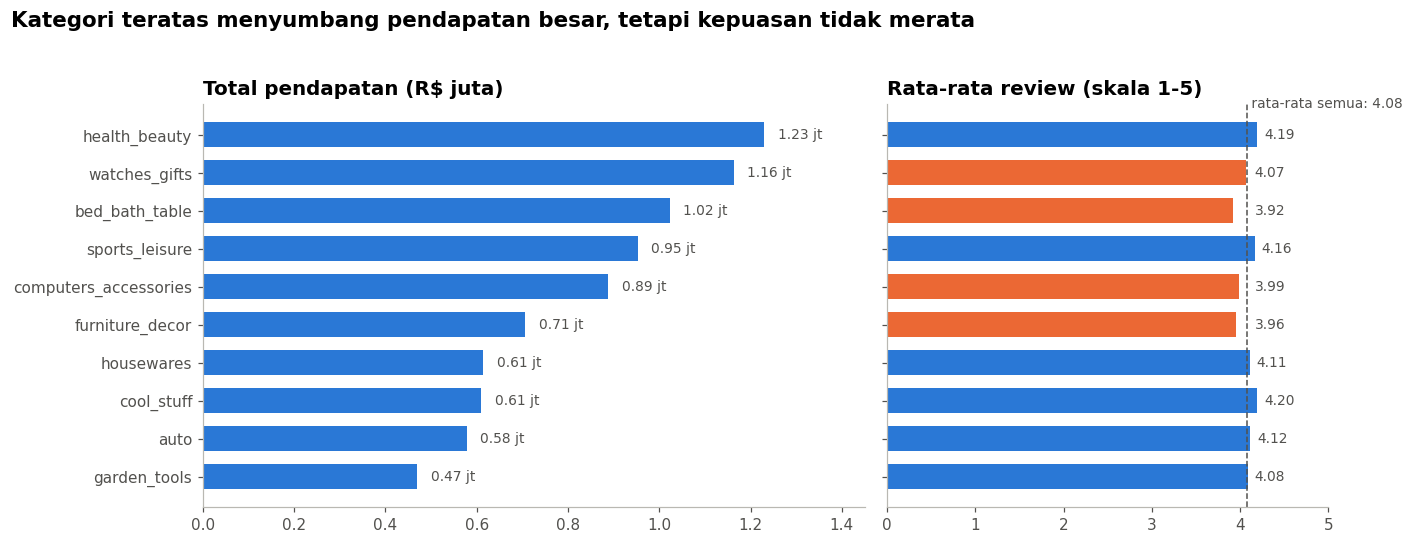

In [27]:
t = top10.sort_values('revenue')
avg_all = main['review_score'].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1.5, 1]}, sharey=True)

axes[0].barh(t.index, t['revenue'] / 1e6, color=BLUE, height=0.65)
for y, v in enumerate(t['revenue'] / 1e6):
    axes[0].text(v + 0.03, y, f'{v:.2f} jt', va='center', color=INK2, fontsize=9)
axes[0].set_title('Total pendapatan (R$ juta)')
axes[0].set_xlim(0, t['revenue'].max() / 1e6 * 1.18)

colors = [ORANGE if v < avg_all else BLUE for v in t['avg_review']]
axes[1].barh(t.index, t['avg_review'], color=colors, height=0.65)
axes[1].axvline(avg_all, color=INK2, lw=1, ls='--')
axes[1].text(avg_all, len(t) - 0.35, f' rata-rata semua: {avg_all:.2f}', color=INK2, fontsize=9, va='bottom')
for y, v in enumerate(t['avg_review']):
    axes[1].text(max(v, avg_all) + 0.08, y, f'{v:.2f}', va='center', color=INK2, fontsize=9)
axes[1].set_xlim(0, 5)
axes[1].set_title('Rata-rata review (skala 1-5)')
fig.suptitle('Kategori teratas menyumbang pendapatan besar, tetapi kepuasan tidak merata', x=0.01, ha='left',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

**Insight:** Sepuluh kategori teratas menyumbang sekitar 62,5% dari total pendapatan (R$ 13,18 juta). `health_beauty` menjadi kategori dengan pendapatan terbesar (R$ 1,23 juta), disusul `watches_gifts` dan `bed_bath_table`. Kategori yang review rata-ratanya berada di bawah rata-rata keseluruhan (4,08, oranye pada grafik kanan) antara lain `bed_bath_table` (3,92), `furniture_decor` (3,96), dan `computers_accessories` (3,99), sehingga ketiganya layak diprioritaskan untuk perbaikan kualitas dan layanan. `health_beauty` (4,19), `cool_stuff` (4,20), dan `sports_leisure` (4,16) memiliki pendapatan besar sekaligus review di atas rata-rata, sehingga cocok menjadi sasaran promosi.

### Pertanyaan 2: keterlambatan pengiriman per state dan dampaknya pada review

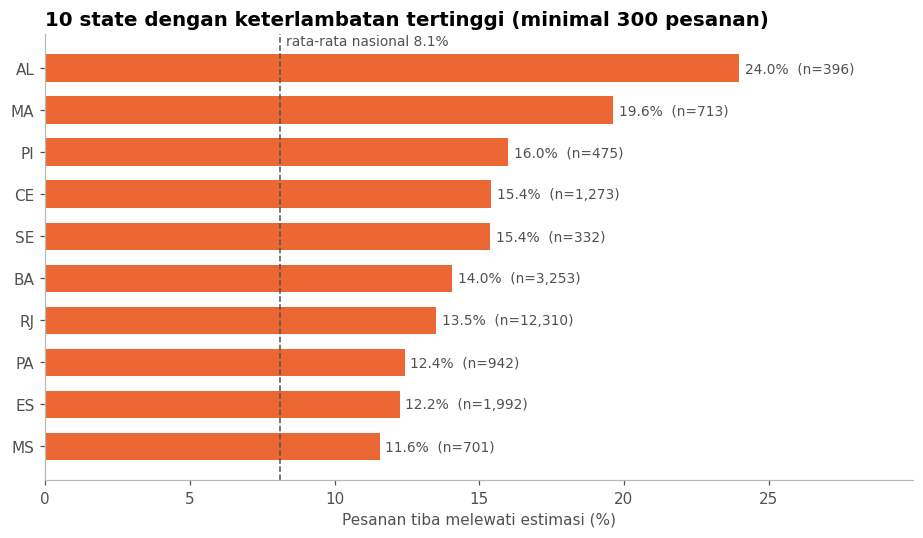

In [28]:
s = state_big.sort_values('late_pct', ascending=False).head(10).sort_values('late_pct')
overall_late = order_level['is_late'].mean() * 100
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(s.index, s['late_pct'], color=[ORANGE if v > overall_late else BLUE for v in s['late_pct']], height=0.65)
ax.axvline(overall_late, color=INK2, lw=1, ls='--')
ax.text(overall_late + 0.2, len(s) - 0.45, f'rata-rata nasional {overall_late:.1f}%', color=INK2, fontsize=9)
for y, (v, n) in enumerate(zip(s['late_pct'], s['orders'])):
    ax.text(v + 0.2, y, f'{v:.1f}%  (n={n:,})', va='center', color=INK2, fontsize=9)
ax.set_xlim(0, s['late_pct'].max() * 1.25)
ax.set_xlabel('Pesanan tiba melewati estimasi (%)')
ax.set_title('10 state dengan keterlambatan tertinggi (minimal 300 pesanan)')
plt.tight_layout(); plt.show()

**Insight:** Rata-rata nasional pesanan terlambat adalah 8,1%. Keterlambatan tertinggi ada di state timur laut: AL (24,0%), MA (19,6%), PI (16,0%), CE (15,4%), SE (15,4%), dan BA (14,1%). RJ juga mencolok (13,5%) karena volumenya besar (sekitar 12 ribu pesanan), sedangkan SP (5,9%), MG (5,6%), dan PR (5,0%) relatif baik. Pesanan terlambat memperoleh review rata-rata 2,57 dibandingkan 4,29 untuk pesanan tepat waktu (selisih 1,72 poin). Pengelompokan berdasarkan lama keterlambatan dan peta sebaran dibahas pada bagian Analisis Lanjutan.

## Analisis Lanjutan (Opsional)

### Binning: selisih hari tiba terhadap estimasi
**Tujuan:** mengelompokkan pesanan ke dalam interval keterlambatan dengan `pd.cut` untuk melihat pada titik mana review mulai turun. Nilai negatif berarti pesanan tiba lebih awal dari estimasi.

In [29]:
bins   = [-np.inf, -14, -7, 0, 3, 7, np.inf]
labels = ['Awal > 14 hr', 'Awal 7-14 hr', 'Awal 0-7 hr', 'Telat 1-3 hr', 'Telat 4-7 hr', 'Telat > 7 hr']
order_level = order_level.copy()
order_level['delay_bin'] = pd.cut(order_level['delay_days'], bins=bins, labels=labels, right=True)
delay_bin = (order_level.groupby('delay_bin', observed=True)
             .agg(orders=('order_id', 'count'), avg_review=('review_score', 'mean')).round(2))
delay_bin['share_%'] = (delay_bin['orders'] / delay_bin['orders'].sum() * 100).round(1)
delay_bin

,orders,avg_review,share_%
delay_bin,,,
Awal > 14 hr,34712,4.32,36.1
Awal 7-14 hr,36351,4.31,37.8
Awal 0-7 hr,17324,4.20,18.0
Telat 1-3 hr,2658,3.76,2.8
Telat 4-7 hr,1819,2.32,1.9
Telat > 7 hr,3339,1.73,3.5


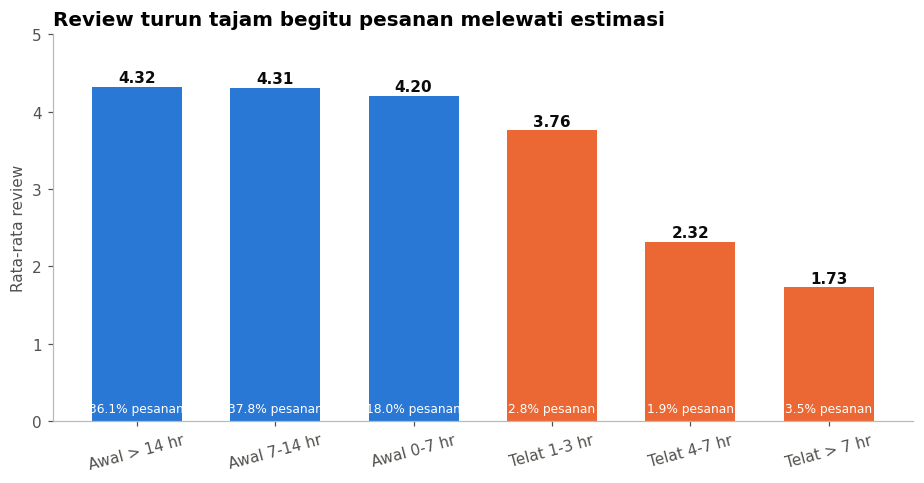

In [30]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = [BLUE if 'Awal' in l else ORANGE for l in delay_bin.index]
ax.bar(delay_bin.index, delay_bin['avg_review'], color=colors, width=0.65)
for x, (v, sh) in enumerate(zip(delay_bin['avg_review'], delay_bin['share_%'])):
    ax.text(x, v + 0.06, f'{v:.2f}', ha='center', color=INK, fontsize=10, fontweight='bold')
    ax.text(x, 0.12, f'{sh:.1f}% pesanan', ha='center', color='white', fontsize=8)
ax.set_ylim(0, 5)
ax.set_ylabel('Rata-rata review')
ax.set_title('Review turun tajam begitu pesanan melewati estimasi')
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

**Insight (Binning):** Sekitar 92% pesanan tiba lebih awal atau tepat estimasi dan review-nya stabil di kisaran 4,2 sampai 4,3. Begitu pesanan melewati estimasi, review turun menjadi 3,76 (telat 1-3 hari), 2,32 (telat 4-7 hari), dan 1,73 (telat lebih dari 7 hari). Dengan kata lain, hanya sekitar 8% pesanan yang terlambat, tetapi dampaknya terhadap kepuasan sangat besar.

### Geospatial Analysis
**Tujuan:** melihat sebaran pelanggan dan keterlambatan secara geografis. Titik tiap state adalah rata-rata koordinat pelanggan di state tersebut, ukuran titik menunjukkan jumlah pesanan, dan warna menunjukkan persentase keterlambatan.

In [31]:
geo_state = (order_level.dropna(subset=['lat', 'lng'])
             .groupby('customer_state')
             .agg(lat=('lat', 'mean'), lng=('lng', 'mean'), orders=('order_id', 'count'),
                  late_pct=('is_late', lambda s: s.mean() * 100)).reset_index())
geo_state.sort_values('orders', ascending=False).head(8).round(2)

,customer_state,lat,lng,orders,late_pct
25,SP,-23.17,-47.05,40385,5.90
18,RJ,-22.76,-43.18,12297,13.53
10,MG,-19.92,-44.44,11310,5.61
22,RS,-29.71,-51.95,5323,7.16
17,PR,-24.81,-50.80,4891,4.95
23,SC,-27.24,-49.56,3537,9.78
4,BA,-13.04,-39.47,3245,13.96
7,ES,-20.16,-40.48,1986,12.13


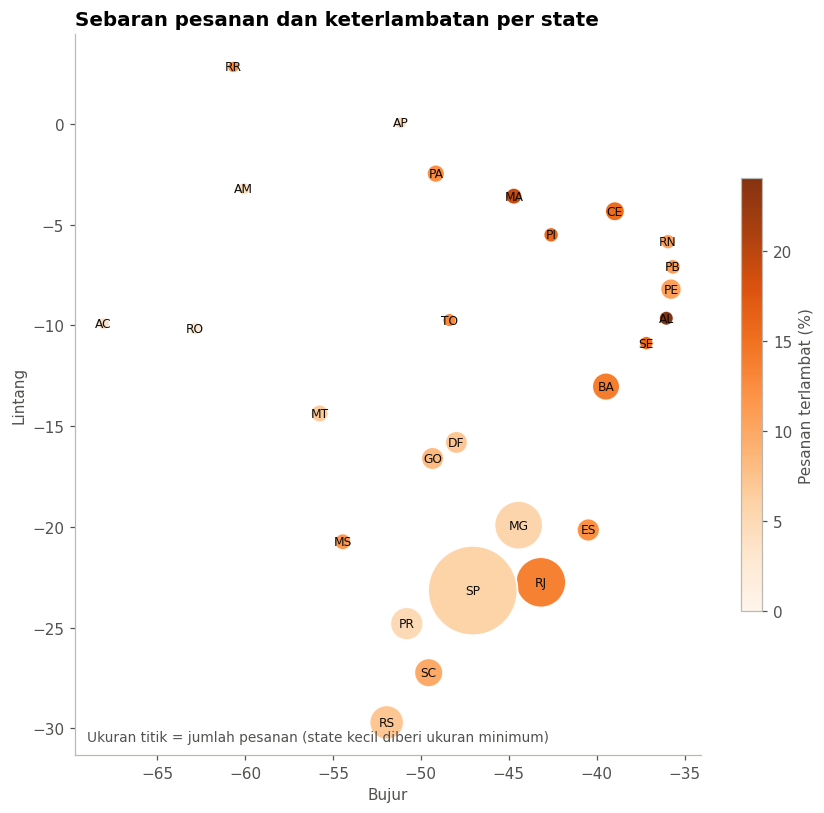

In [32]:
fig, ax = plt.subplots(figsize=(8, 7.5))
sc = ax.scatter(geo_state['lng'], geo_state['lat'], s=60 + geo_state['orders'] / 12, c=geo_state['late_pct'],
                cmap='Oranges', edgecolor='white', linewidth=1.2, alpha=0.95, vmin=0)
for _, r in geo_state.iterrows():
    ax.annotate(r['customer_state'], (r['lng'], r['lat']), ha='center', va='center', fontsize=8, color=INK)
cb = plt.colorbar(sc, ax=ax, shrink=0.6); cb.set_label('Pesanan terlambat (%)')
ax.set_xlabel('Bujur'); ax.set_ylabel('Lintang')
ax.set_title('Sebaran pesanan dan keterlambatan per state')
ax.text(0.02, 0.02, 'Ukuran titik = jumlah pesanan (state kecil diberi ukuran minimum)', transform=ax.transAxes, color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

**Insight (Geospatial):** Titik oranye pekat berada di timur laut (AL, MA, PI, CE, SE, BA) dan di RJ, sedangkan titik besar SP dan MG berwarna terang. Artinya volume pesanan terbesar berada di wilayah dengan keterlambatan rendah, sehingga perbaikan logistik paling berdampak bila diarahkan ke timur laut dan RJ.

### RFM Analysis (menjawab Pertanyaan 3)
**Tujuan:** mengelompokkan pelanggan berdasarkan perilaku belanja.
- **Recency:** jumlah hari sejak pembelian terakhir sampai tanggal acuan 1 September 2018.
- **Frequency:** jumlah pesanan unik per `customer_unique_id`.
- **Monetary:** total `price + freight_value` seluruh pesanan pelanggan.

Segmen dibuat dengan *manual grouping* berbasis aturan bisnis, bukan algoritma machine learning. Aturan ini dipilih karena sekitar 97% pelanggan hanya membeli satu kali, sehingga pembagian kuantil untuk Frequency tidak akan membedakan pelanggan.

In [33]:
ref_date = pd.Timestamp('2018-09-01')
rfm = (main.groupby('customer_unique_id')
           .agg(last_order=('order_purchase_timestamp', 'max'),
                frequency=('order_id', 'nunique'),
                monetary=('total_value', 'sum')).reset_index())
rfm['recency'] = (ref_date - rfm['last_order']).dt.days
print('Pelanggan hanya 1 kali beli: {:.1f}%'.format((rfm['frequency'] == 1).mean() * 100))
print(rfm[['recency', 'frequency', 'monetary']].describe().round(1))

Pelanggan hanya 1 kali beli: 97.0%
       recency  frequency  monetary
count  93096.0    93096.0   93096.0
mean     238.2        1.0     165.1
std      150.9        0.2     226.4
min        2.0        1.0       9.6
25%      116.0        1.0      63.0
50%      220.0        1.0     107.8
75%      347.0        1.0     182.4
max      603.0       15.0   13664.1


In [34]:
high_value = rfm['monetary'].quantile(0.75)   # 25% pelanggan dengan belanja terbesar
def segment(r):
    if r.frequency >= 2:
        return 'Loyal (repeat, aktif)' if r.recency <= 180 else 'Repeat (perlu diaktifkan)'
    if r.recency <= 90:
        return 'Baru bernilai tinggi' if r.monetary >= high_value else 'Baru'
    if r.recency <= 270:
        return 'Win-back bernilai tinggi' if r.monetary >= high_value else 'Mulai pasif'
    return 'Hilang (> 270 hari)'

rfm['segment'] = rfm.apply(segment, axis=1)
seg = (rfm.groupby('segment')
          .agg(pelanggan=('customer_unique_id', 'count'), revenue=('monetary', 'sum'),
               avg_monetary=('monetary', 'mean'), avg_recency=('recency', 'mean')))
seg['pelanggan_%'] = (seg['pelanggan'] / seg['pelanggan'].sum() * 100).round(1)
seg['revenue_%'] = (seg['revenue'] / seg['revenue'].sum() * 100).round(1)
seg = seg.sort_values('revenue', ascending=False)
print('Batas belanja tinggi (kuartil 3): R$ {:.0f}'.format(high_value))
seg.round(1)

Batas belanja tinggi (kuartil 3): R$ 182


,pelanggan,revenue,avg_monetary,avg_recency,pelanggan_%,revenue_%
segment,,,,,,
Hilang (> 270 hari),35845,5797057.5,161.7,395.3,38.5,37.7
Win-back bernilai tinggi,8759,3339222.1,381.2,177.4,9.4,21.7
Mulai pasif,28102,2512461.3,89.4,179.1,30.2,16.3
Baru bernilai tinggi,4258,1669449.9,392.1,47.0,4.6,10.9
Baru,13343,1193017.1,89.4,45.4,14.3,7.8
Repeat (perlu diaktifkan),1572,468792.7,298.2,321.5,1.7,3.0
"Loyal (repeat, aktif)",1217,391740.5,321.9,91.4,1.3,2.5


#### Visualisasi segmentasi pelanggan (RFM)

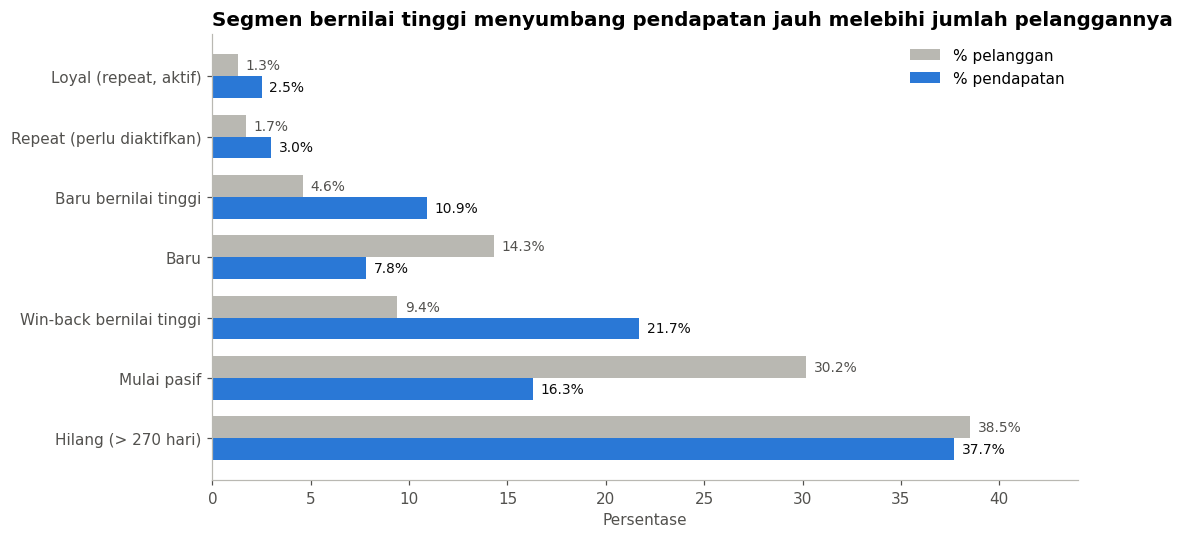

In [35]:
order_seg = ['Loyal (repeat, aktif)', 'Repeat (perlu diaktifkan)', 'Baru bernilai tinggi', 'Baru',
             'Win-back bernilai tinggi', 'Mulai pasif', 'Hilang (> 270 hari)']
sg = seg.reindex(order_seg)
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(sg))[::-1]
h = 0.36
ax.barh(y + h / 2, sg['pelanggan_%'], height=h, color=GREY, label='% pelanggan')
ax.barh(y - h / 2, sg['revenue_%'], height=h, color=BLUE, label='% pendapatan')
for yy, a, b in zip(y, sg['pelanggan_%'], sg['revenue_%']):
    ax.text(a + 0.4, yy + h / 2, f'{a:.1f}%', va='center', fontsize=9, color=INK2)
    ax.text(b + 0.4, yy - h / 2, f'{b:.1f}%', va='center', fontsize=9, color=INK)
ax.set_yticks(y); ax.set_yticklabels(sg.index)
ax.set_xlabel('Persentase'); ax.legend(frameon=False, loc='upper right')
ax.set_xlim(0, 44)
ax.set_title('Segmen bernilai tinggi menyumbang pendapatan jauh melebihi jumlah pelanggannya')
plt.tight_layout(); plt.show()

**Insight (RFM, Pertanyaan 3):** Sebanyak 97% pelanggan hanya membeli satu kali. Segmen *Hilang* (lebih dari 270 hari tidak bertransaksi) mencakup 38,5% pelanggan dan 37,7% pendapatan. Dua segmen bernilai tinggi (*Win-back bernilai tinggi* dan *Baru bernilai tinggi*) hanya 14,0% pelanggan tetapi menyumbang 32,6% pendapatan, dengan rata-rata belanja sekitar R$ 380-390 per pelanggan dibanding R$ 89 pada segmen biasa. Pelanggan berulang (*Loyal* dan *Repeat*) hanya sekitar 3% pelanggan, sehingga retensi menjadi peluang terbesar.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepuluh kategori teratas menguasai sekitar 62,5% pendapatan Januari 2017 sampai Agustus 2018. `health_beauty` memimpin pendapatan dengan review di atas rata-rata, sedangkan `bed_bath_table`, `furniture_decor`, dan `computers_accessories` memiliki pendapatan besar tetapi review di bawah rata-rata keseluruhan.
- **Conclusion pertanyaan 2:** Keterlambatan sangat tidak merata antar state: AL, MA, PI, CE, SE, BA, dan RJ berada jauh di atas rata-rata nasional 8,1%. Keterlambatan merusak kepuasan: review pesanan terlambat 1,72 poin lebih rendah (2,57 vs 4,29) dan menurun semakin lama keterlambatannya.
- **Conclusion pertanyaan 3:** Sebanyak 97% pelanggan hanya membeli sekali dan 38,5% sudah lebih dari 270 hari tidak kembali. Segmen bernilai tinggi (14,0% pelanggan) menyumbang 32,6% pendapatan, sehingga menjadi sasaran retensi yang paling efisien.

**Rekomendasi Action Item:**
1. **Promosi dan kualitas kategori.** Alokasikan anggaran promosi ke `health_beauty`, `cool_stuff`, dan `sports_leisure`. Audit kualitas produk dan penjual pada `bed_bath_table`, `furniture_decor`, dan `computers_accessories` karena review rendah di kategori berpendapatan besar menggerus reputasi.
2. **Logistik.** Perbaiki estimasi pengiriman (buffer lebih realistis) dan evaluasi mitra kurir untuk state dengan persentase terlambat tertinggi (AL, MA, PI, CE, SE, BA, RJ). Pantau indikator keterlambatan > 7 hari karena dampaknya terhadap review paling besar.
3. **Retensi.** Jalankan kampanye *win-back* (voucher atau ongkir gratis) untuk segmen *Win-back bernilai tinggi* dan *Baru bernilai tinggi* sebelum mereka berpindah ke segmen *Hilang*, dan terapkan program ajakan pembelian kedua dalam 90 hari setelah pembelian pertama.